In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('Iris.csv')

In [3]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
df = df.iloc[:,1:]

In [5]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
from sklearn.preprocessing import LabelEncoder

In [7]:
encoder = LabelEncoder()

In [8]:
df['Species'] = encoder.fit_transform(df['Species'])

In [9]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [10]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]

In [11]:
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

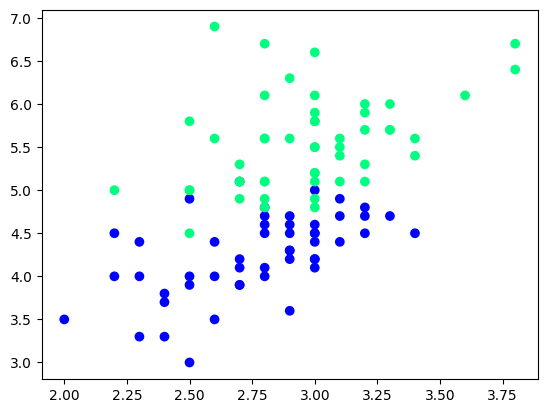

In [13]:
plt.scatter(df['SepalWidthCm'],df['PetalLengthCm'],c=df['Species'],cmap='winter')

In [14]:
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(10)
df_test = df.iloc[80:,:].sample(10)

In [15]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [16]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [17]:
y_test

array([1, 2, 2, 2, 1, 2, 2, 1, 1, 1])

## Case 1 - Bagging

In [18]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
71,2.8,4.0,1
128,2.8,5.6,2
72,2.5,4.9,1
128,2.8,5.6,2
71,2.8,4.0,1
127,3.0,4.9,2
71,2.8,4.0,1


In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [20]:
dt_bag1 = DecisionTreeClassifier()

In [21]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))
    

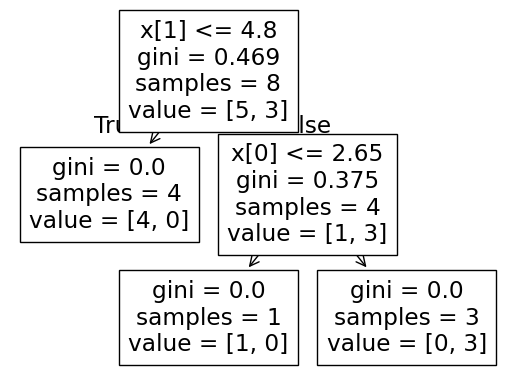

c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.9


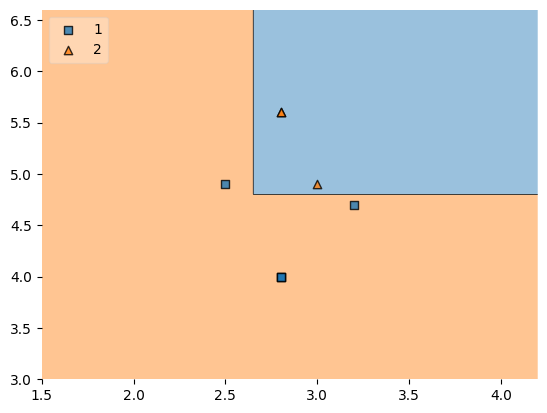

In [22]:
evaluate(dt_bag1,X,y)

In [23]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
64,2.9,3.6,1
71,2.8,4.0,1
64,2.9,3.6,1
86,3.1,4.7,1
118,2.6,6.9,2
71,2.8,4.0,1
86,3.1,4.7,1
120,3.2,5.7,2


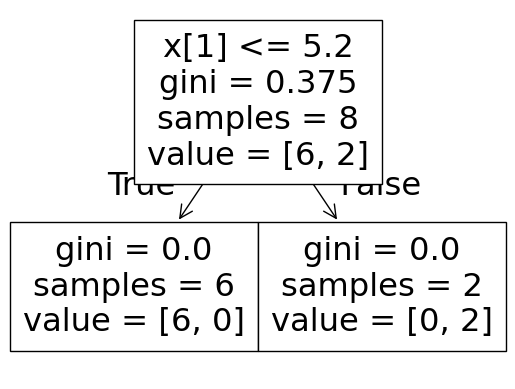

c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.9


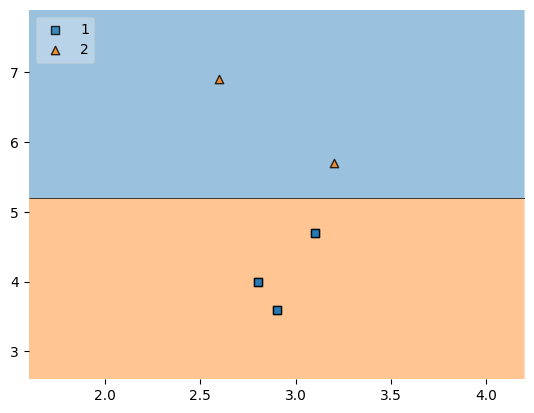

In [24]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [25]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
128,2.8,5.6,2
50,3.2,4.7,1
86,3.1,4.7,1
50,3.2,4.7,1
50,3.2,4.7,1
118,2.6,6.9,2
118,2.6,6.9,2
86,3.1,4.7,1


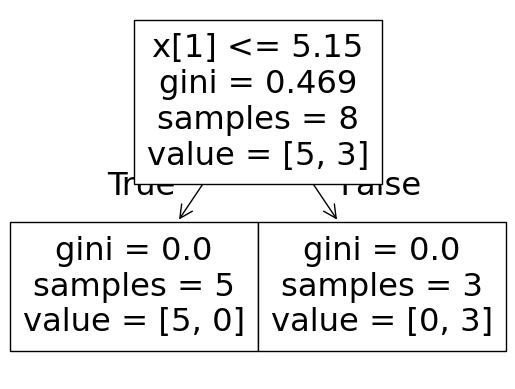

c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.9


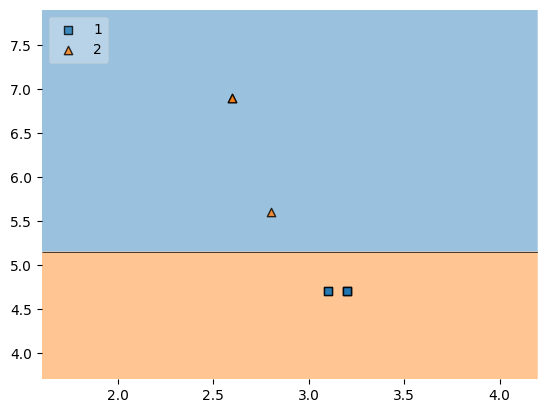

In [26]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

## Predict

In [27]:
df_test

,SepalWidthCm,PetalLengthCm,Species
80,2.4,3.8,1
123,2.7,4.9,2
62,2.2,4.0,1
133,2.8,5.1,2
144,3.3,5.7,2
95,3.0,4.2,1
110,3.2,5.1,2
97,2.9,4.3,1
130,2.8,6.1,2
131,3.8,6.4,2


In [31]:
print("Predictor 1",dt_bag1.predict(np.array([2.2,4.0]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.2,4.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.2,4.0]).reshape(1,2)))

Predictor 1 [1]
Predictor 2 [1]
Predictor 3 [1]


c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Program Files\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


## Pasting

In [29]:
# Row sampling without replacement
df_train

,SepalWidthCm,PetalLengthCm,Species
127,3.0,4.9,2
128,2.8,5.6,2
71,2.8,4.0,1
120,3.2,5.7,2
86,3.1,4.7,1
142,2.7,5.1,2
72,2.5,4.9,1
50,3.2,4.7,1
64,2.9,3.6,1
118,2.6,6.9,2


In [30]:
df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
128,2.8,5.6,2
142,2.7,5.1,2
71,2.8,4.0,1
64,2.9,3.6,1
120,3.2,5.7,2
118,2.6,6.9,2
127,3.0,4.9,2
86,3.1,4.7,1


## Random Subspaces

In [32]:
df1 = pd.read_csv('Iris.csv')
df1 = df1.sample(10)

In [33]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
107,108,7.3,2.9,6.3,1.8,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
65,66,6.7,3.1,4.4,1.4,Iris-versicolor
27,28,5.2,3.5,1.5,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
78,79,6.0,2.9,4.5,1.5,Iris-versicolor
33,34,5.5,4.2,1.4,0.2,Iris-setosa
89,90,5.5,2.5,4.0,1.3,Iris-versicolor
116,117,6.5,3.0,5.5,1.8,Iris-virginica
94,95,5.6,2.7,4.2,1.3,Iris-versicolor


In [34]:
df1.sample(2,replace=True,axis=1)

,SepalLengthCm,PetalWidthCm
107,7.3,1.8
146,6.3,1.9
65,6.7,1.4
27,5.2,0.2
3,4.6,0.2
78,6.0,1.5
33,5.5,0.2
89,5.5,1.3
116,6.5,1.8
94,5.6,1.3


## Random Patches

In [35]:
   df1 

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
107,108,7.3,2.9,6.3,1.8,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
65,66,6.7,3.1,4.4,1.4,Iris-versicolor
27,28,5.2,3.5,1.5,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
78,79,6.0,2.9,4.5,1.5,Iris-versicolor
33,34,5.5,4.2,1.4,0.2,Iris-setosa
89,90,5.5,2.5,4.0,1.3,Iris-versicolor
116,117,6.5,3.0,5.5,1.8,Iris-virginica
94,95,5.6,2.7,4.2,1.3,Iris-versicolor


In [36]:
df1.sample(8,replace=True).sample(2,replace=True,axis=1)

,PetalLengthCm,PetalLengthCm
27,1.5,1.5
27,1.5,1.5
146,5.0,5.0
116,5.5,5.5
107,6.3,6.3
146,5.0,5.0
33,1.4,1.4
116,5.5,5.5
